# Contexto de Negócio e Setup

O PaySim é um dos datasets mais clássicos para classificação de risco financeiro. Baseado em transações bancárias sintéticas, ele é um ótimo referencial fictício para meu primeiro modelo com foco em deploy.

**Objetivo de negócio:**
Mapear e identificar de maneira preditiva transações fraudulentas, permitindo uma reação rápida perante infrações sem penalizar transações legítimas.

Esta automação possibilitará à instituição fictícia manter conformidade com as diretrizes regulatórias e exigências de auditoria.

## Importação de Bibliotecas necessárias e Seeds para Reprodutibilidade

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import os
import numpy as np

In [ ]:
#Importando do Kaggle
path = kagglehub.dataset_download("mtalaltariq/paysim-data")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'paysim-data' dataset.
Path to dataset files: /kaggle/input/paysim-data


## Ingestão dos dados


In [ ]:
f_path= f'{path}/paysim dataset.csv'
base= pd.read_csv(f_path)

base.info()
base.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:
x=base.drop(columns=['isFlaggedFraud','isFraud','nameOrig', 'nameDest'],axis=1)
y=base['isFraud']

# Análise exploratória e Feature Engineering

## Variáveis de Data

In [ ]:
## Transformando o Step

x['hour']= x['step'] % 24

x['day_of_week']= (x['step']//24) % 7

x['day_of_month']= (x['step']//24) + 1

In [ ]:
def plot_barras(X, y, campo_x, titulo, cores=['#7B2CBF', '#FF3366'], normalize=False, apenas=None, stacked=True, salvar_como=None):
    fig, ax = plt.subplots(figsize=(10, 6))

    fig.patch.set_facecolor('#121212')
    ax.set_facecolor('#121212')

    norm_opcao = 'index' if normalize else False
    df_plot = pd.crosstab(X[campo_x], y, normalize=norm_opcao)

    if normalize:
        df_plot = df_plot * 100

    if apenas is not None:
        df_plot = df_plot[[apenas]]
        stacked = False
        cor_usada = [cores[-1]] if isinstance(cores, list) and len(cores) > 1 else cores
    else:
        cor_usada = cores

    df_plot.plot(kind='bar', stacked=stacked, ax=ax, color=cor_usada)

    ax.set_title(titulo, color='white', fontsize=13, pad=12)
    ax.set_xlabel(campo_x, color='white', fontsize=11)
    ax.set_ylabel('Proporção (%)' if normalize else 'Quantidade', color='white', fontsize=11)
    ax.tick_params(colors='white', rotation= 25)

    if apenas is not None:
        if ax.get_legend():
            ax.legend().remove()
    else:
        nome_y = y.name if hasattr(y, 'name') and y.name else 'y'
        ax.legend(title=nome_y, facecolor='#1e1e1e', edgecolor='none', labelcolor='white')

    plt.tight_layout()

    if salvar_como:
        os.makedirs('assets', exist_ok=True)
        plt.savefig(salvar_como, bbox_inches='tight', dpi=300, facecolor=fig.get_facecolor())

    plt.show()

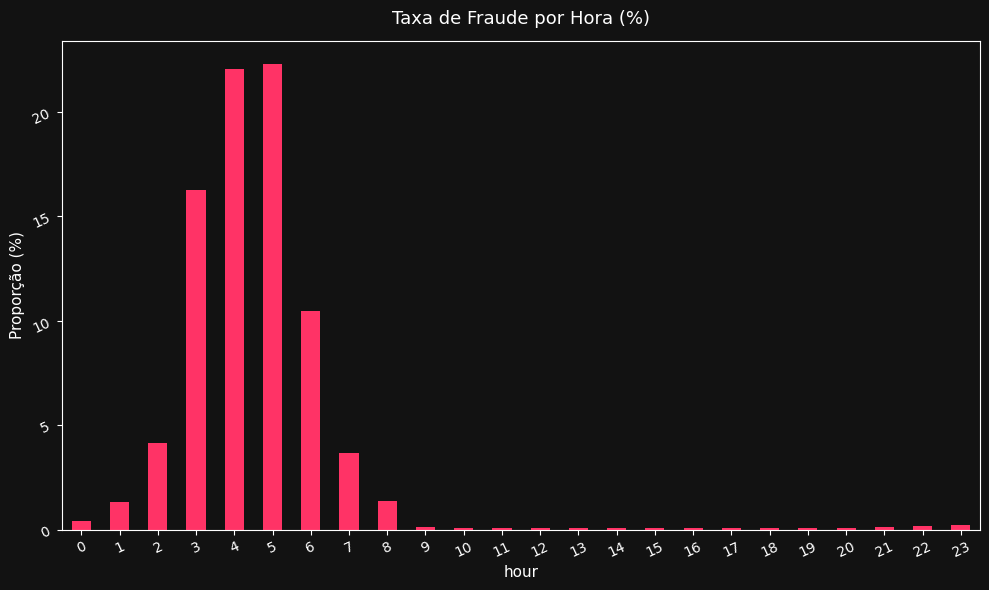

In [ ]:
plot_barras(
    X=x,
    y=y,
    campo_x='hour',
    titulo='Taxa de Fraude por Hora (%)',
    normalize=True,
    apenas=1,
    salvar_como='assets/taxa_fraude_hora.png'
)

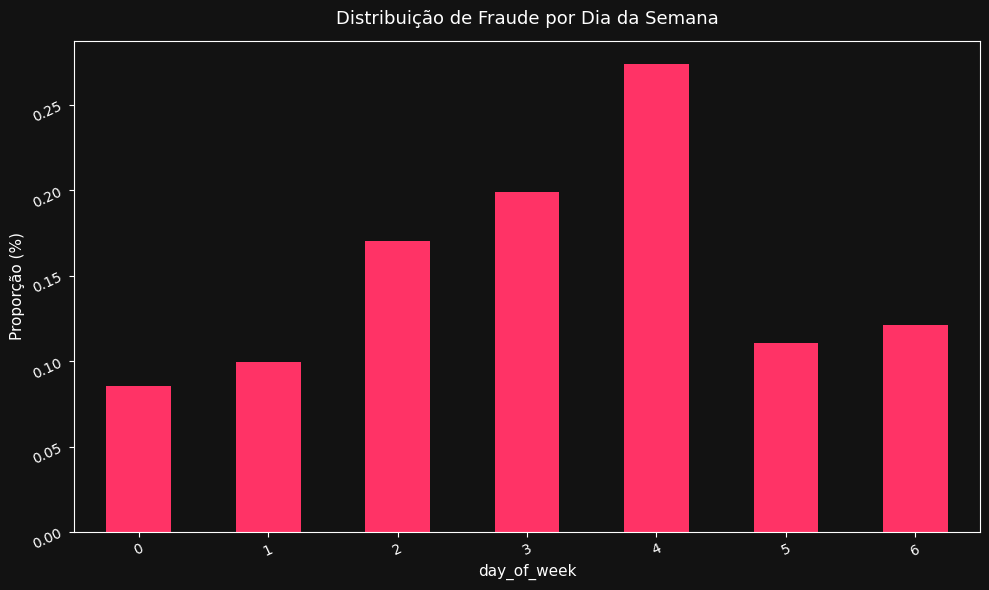

In [ ]:
plot_barras(
    X=x,
    y=y,
    campo_x='day_of_week',
    titulo='Distribuição de Fraude por Dia da Semana',
    normalize=True,
    apenas=1,
    salvar_como='assets/fraude_por_dia_semana.png'
)

Analisando a distribuição por dia da semana, observa-se um comportamento relativamente homogêneo, principalmente se olharmos as médias, que ficam dentro do intervalo de dois desvios-padrão. Por isso, o campo representa ruído e será removido da base.

In [ ]:
x= x.drop(columns='day_of_week',axis=1)
list(x.columns)

['step',
 'type',
 'amount',
 'oldbalanceOrg',
 'newbalanceOrig',
 'oldbalanceDest',
 'newbalanceDest',
 'hour',
 'day_of_month']

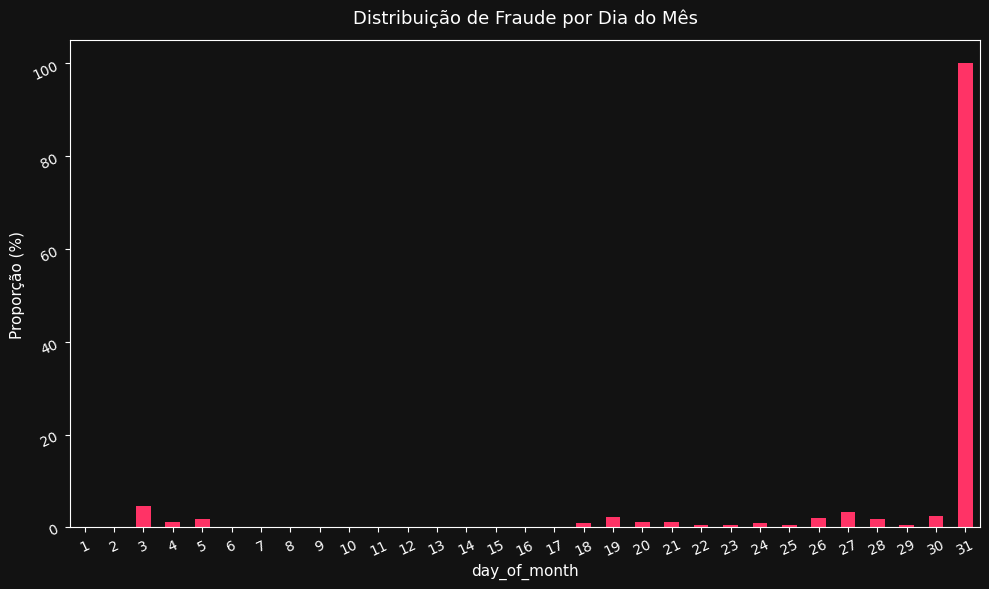

In [ ]:
plot_barras(
    X=x,
    y=y,
    campo_x='day_of_month',  # confira se a coluna está com esse nome ou com 'day_of_month'
    titulo='Distribuição de Fraude por Dia do Mês',
    apenas=1,
    normalize=True,
    salvar_como='assets/fraude_por_dia_mes.png'
)

## Variáveis Categóricas

In [ ]:
colunas_obj= [c for c in x.columns if x[c].dtype == 'O' ]
colunas_obj

['type']

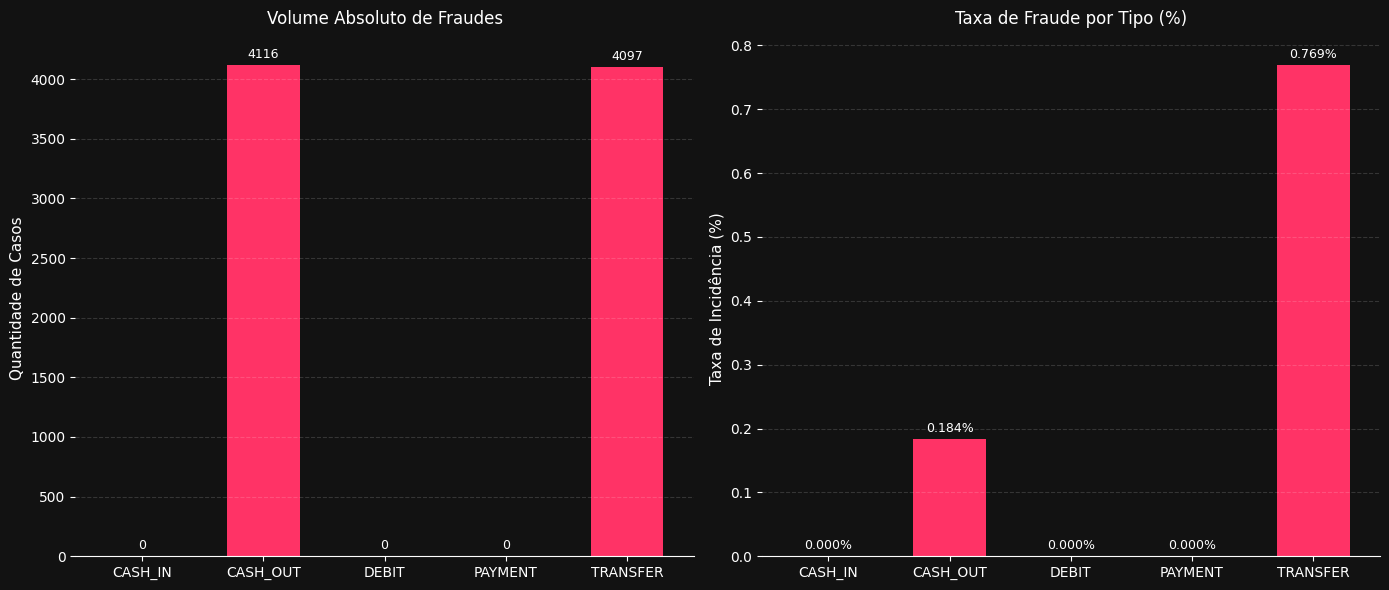

In [ ]:
# Se ainda estiver usando x e y separados, basta trocar base['type'] por x['type'] e base['isFraud'] por y
plt.style.use("dark_background")
df_plot = pd.crosstab(base['type'], base['isFraud'])
df_plot_n = pd.crosstab(base['type'], base['isFraud'], normalize='index') * 100

# Filtra estritamente a coluna de fraudes (1)
fraude_abs = df_plot[1]
fraude_pct = df_plot_n[1]

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor('#121212')
cor_fraude = '#FF3366'

# 1. Volume Absoluto (apenas fraudes)
fraude_abs.plot(kind='bar', ax=ax[0], color=cor_fraude, width=0.6)
ax[0].set_title('Volume Absoluto de Fraudes', color='white', fontsize=12, pad=12)
ax[0].set_facecolor('#121212')
ax[0].set_xlabel('')
ax[0].set_ylabel('Quantidade de Casos', color='white', fontsize=11)
ax[0].tick_params(colors='white', rotation=0)

for container in ax[0].containers:
    ax[0].bar_label(container, fmt='%d', padding=3, color='white', fontsize=9)

# 2. Taxa Proporcional (%) (apenas fraudes)
fraude_pct.plot(kind='bar', ax=ax[1], color=cor_fraude, width=0.6)
ax[1].set_title('Taxa de Fraude por Tipo (%)', color='white', fontsize=12, pad=12)
ax[1].set_facecolor('#121212')
ax[1].set_xlabel('')
ax[1].set_ylabel('Taxa de Incidência (%)', color='white', fontsize=11)
ax[1].tick_params(colors='white', rotation=0)

for container in ax[1].containers:
    ax[1].bar_label(container, fmt='%.3f%%', padding=3, color='white', fontsize=9)

# Estilização dos eixos
for a in ax:
    for spine in ['top', 'right', 'left']:
        a.spines[spine].set_visible(False)
    a.yaxis.grid(True, linestyle='--', alpha=0.15, color='white')

plt.tight_layout()

os.makedirs('assets', exist_ok=True)
plt.savefig('assets/analise_tipo_transacao.png', bbox_inches='tight', dpi=300, facecolor=fig.get_facecolor())
plt.show()

É notório que apenas dois tipos de transação apresentam fraudes: `CASH_OUT` e `TRANSFER`. Portanto, as demais modalidades serão removidas da base.

In [ ]:
#Cria a máscara com os dois tipos relevantes
mascara = x['type'].isin(['TRANSFER', 'CASH_OUT'])

#Aplica o filtro em X e y ao mesmo tempo
x = x[mascara].copy().reset_index(drop=True)
y= y[mascara].copy().reset_index(drop=True)

In [ ]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2770409 entries, 0 to 2770408
Data columns (total 9 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   oldbalanceOrg   float64
 4   newbalanceOrig  float64
 5   oldbalanceDest  float64
 6   newbalanceDest  float64
 7   hour            int64  
 8   day_of_month    int64  
dtypes: float64(5), int64(3), object(1)
memory usage: 190.2+ MB


## Variáveis Numéricas

In [ ]:
x.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,hour,day_of_month
count,2.770409e+06,2.770409e+06,2.770409e+06,2.770409e+06,2.770409e+06,2.770409e+06,2.770409e+06,2.770409e+06
mean,2.420081e+02,3.175361e+05,4.764308e+04,1.609190e+04,1.703551e+06,2.049734e+06,1.530878e+01,1.044580e+01
std,1.416191e+02,8.877897e+05,2.513251e+05,1.512558e+05,4.225550e+06,4.676990e+06,4.004595e+00,5.893392e+00
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
25%,1.550000e+02,8.297354e+04,0.000000e+00,0.000000e+00,1.280734e+05,3.272891e+05,1.200000e+01,7.000000e+00
50%,2.360000e+02,1.712609e+05,3.039600e+02,0.000000e+00,5.557100e+05,8.280539e+05,1.600000e+01,1.000000e+01
75%,3.320000e+02,3.067912e+05,3.099700e+04,0.000000e+00,1.735900e+06,2.122198e+06,1.900000e+01,1.400000e+01
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,2.300000e+01,3.100000e+01


In [ ]:
def plot_boxplot(dataframe, colunas, campo_alvo='isFraud', titulo='', log=False, salvar_como=None):
    if isinstance(colunas, str):
        colunas = [colunas]

    n = len(colunas)
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 5), squeeze=False)
    fig.patch.set_facecolor('#121212')
    paleta = ['#7B2CBF', '#FF3366']

    for ax, col in zip(axes[0], colunas):
        ax.set_facecolor('#121212')

        sns.boxplot(data=dataframe, x=campo_alvo, y=col, ax=ax, palette=paleta, hue=campo_alvo)

        if log:
            ax.set_yscale('log')
            ax.set_ylabel(f'{col} (Escala Log)', color='white', fontsize=11)
        else:
            ax.set_ylabel(col, color='white', fontsize=11)

        ax.set_xlabel(campo_alvo, color='white', fontsize=11)
        ax.set_title(f'{titulo} {col}'.strip(), color='white', fontsize=12, pad=12)
        ax.tick_params(colors='white')
        ax.yaxis.grid(True, linestyle='--', alpha=0.15, color='white')

        for spine in ['top', 'right', 'left']:
            ax.spines[spine].set_visible(False)

    plt.tight_layout()

    if salvar_como:
        os.makedirs('assets', exist_ok=True)
        plt.savefig(salvar_como, bbox_inches='tight', dpi=300, facecolor=fig.get_facecolor())

    plt.show()

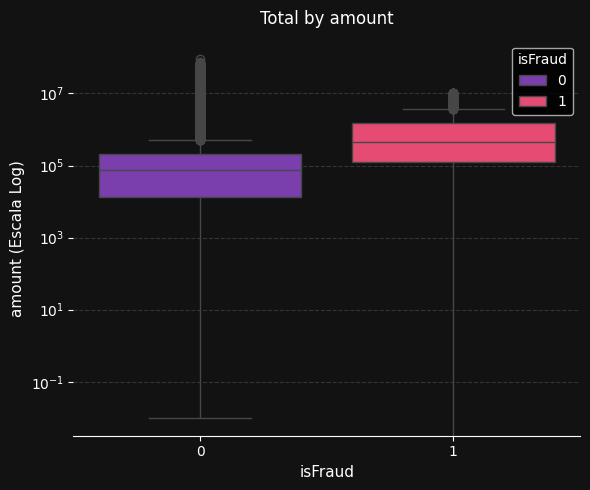

In [ ]:
plot_boxplot(
    dataframe=base,
    colunas='amount',
    campo_alvo='isFraud',
    titulo='Total by',
    log=True,
    salvar_como='assets/boxplot_amount.png'
)

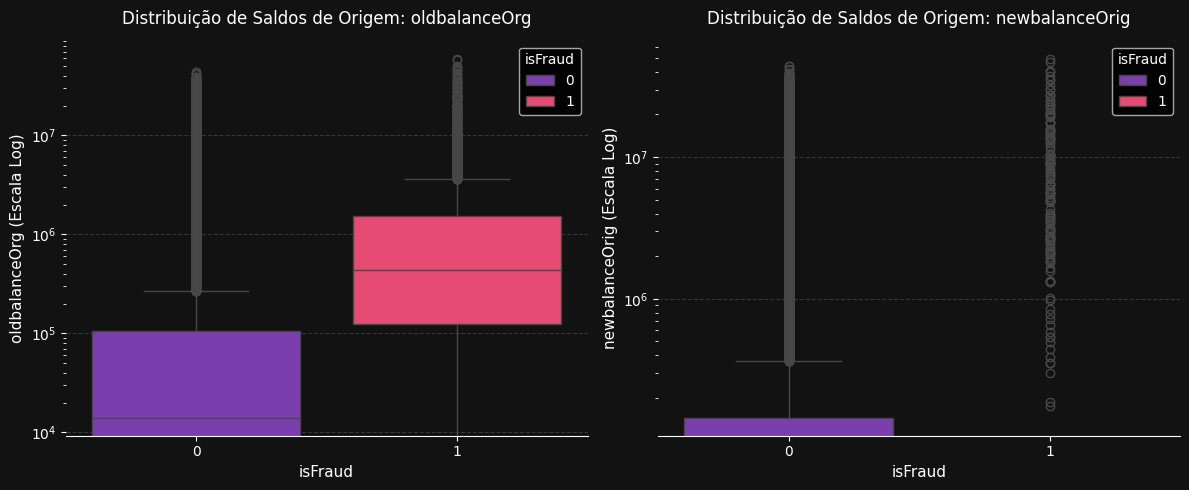

In [ ]:
plot_boxplot(
    dataframe=base,
    colunas=['oldbalanceOrg', 'newbalanceOrig'],
    campo_alvo='isFraud',
    titulo='Distribuição de Saldos de Origem:',
    log=True,
    salvar_como='assets/boxplot_saldos_origem.png'
)

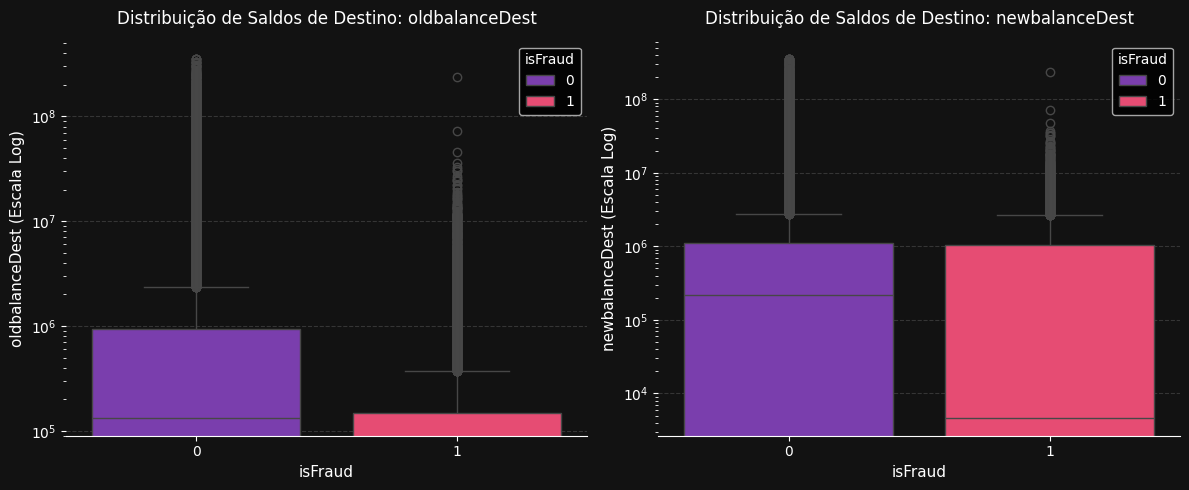

In [ ]:
plot_boxplot(
    dataframe=base,
    colunas=['oldbalanceDest', 'newbalanceDest'],
    campo_alvo='isFraud',
    titulo='Distribuição de Saldos de Destino:',
    log=True,
    salvar_como='assets/boxplot_saldos_destino.png'
)

### Criando os campos de erro de saldo de Origem e Destino

No PaySim, há inconsistências contábeis sistemáticas nas transações que funcionam como fortes preditores de fraude. Em um fluxo financeiro íntegro, as equações de saldo devem fechar em zero:

* **Origem:** $\text{Saldo Antigo} - \text{Valor} = \text{Novo Saldo}$
* **Destino:** $\text{Saldo Antigo} + \text{Valor} = \text{Novo Saldo}$

Em diversas transações fraudulentas, essas relações colapsam: contas de origem realizam transferências milionárias mesmo com saldo registrado como zero, ou contas de destino não têm o saldo final creditado na simulação. A quantificação desses desvios contábeis gera duas features cruciais para o modelo: `errorBalanceOrig` e `errorBalanceDest`.

In [ ]:

x['error_orig'] =x['oldbalanceOrg'] - x['amount'] - x['newbalanceOrig']


x['error_dest'] = x['oldbalanceDest'] + x['amount'] - x['newbalanceDest']

# FLAG DE CONTA DE DESTINO FANTASMA
x['dest_zero_flag'] = ((x['oldbalanceDest'] == 0) & (x['newbalanceDest'] == 0)).astype(int)

In [ ]:
media_erros = x[['error_orig', 'error_dest']].groupby(y).mean()

display(media_erros.applymap(lambda v: f"{v:,.2f}"))

/tmp/ipykernel_1163/4104615097.py:3: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  display(media_erros.applymap(lambda v: f"{v:,.2f}"))


,error_orig,error_dest
isFraud,,
0,"-286,803.51","-30,910.33"
1,"-10,692.33","732,509.30"


# Preparação e Estratégia de Validação

## Treino, Validação e Teste

In [ ]:
from sklearn.model_selection import train_test_split

x_temp, x_test, y_temp, y_test= train_test_split(x,y,test_size=0.15, random_state=10,stratify=y)

In [ ]:
x_train,x_val,y_train,y_val= train_test_split(x_temp,y_temp, test_size=0.20, random_state=10, stratify=y_temp)



## Pipeline de processamento

In [ ]:
#TRANSFORMANDO O CONJUNTO DE TREINAMENTO
from sklearn.preprocessing import OneHotEncoder

one_hot= OneHotEncoder(drop='if_binary', sparse_output=False)

col_encoded_array = one_hot.fit_transform(x_train[colunas_obj])

colunas=one_hot.get_feature_names_out(colunas_obj)

col_encoded = pd.DataFrame(
    col_encoded_array,
    columns=colunas,
    index=x_train.index,
)

x_train = pd.concat([x_train.drop(columns=colunas_obj), col_encoded], axis=1)

x_train.head()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,hour,day_of_month,error_orig,error_dest,dest_zero_flag,type_TRANSFER
33373,10,210088.27,1070971.39,860883.11,883142.50,1093230.77,10,1,0.01,0.00,0,0.0
456287,94,42821.21,29719.00,0.00,1442644.08,1485465.29,22,4,-13102.21,0.00,0,0.0
2584804,403,276379.27,0.00,0.00,2204271.90,2480651.16,19,17,-276379.27,0.01,0,0.0
689192,155,104597.55,36162.00,0.00,0.00,104597.55,11,7,-68435.55,0.00,0,0.0
1226091,216,95541.17,16212.09,0.00,1587563.97,1683105.14,0,10,-79329.08,0.00,0,0.0


In [ ]:
# VALIDAÇÃO E TESTE
def one_hot_val_test(df:pd.DataFrame) -> pd.DataFrame:

        col_encoded_array= one_hot.transform(df[colunas_obj])

        colunas=one_hot.get_feature_names_out(colunas_obj)

        col_encoded= pd.DataFrame(
            col_encoded_array,
            columns=colunas,
            index=df.index
        )

        return pd.concat([df.drop(columns=colunas_obj), col_encoded], axis=1)

x_val=one_hot_val_test(x_val)
x_test=one_hot_val_test(x_test)

In [ ]:
from sklearn.preprocessing import StandardScaler
col_norm= x_train.columns[2:6]

normalizer= StandardScaler()

x_train[col_norm]= normalizer.fit_transform(x_train[col_norm])

# APLICANDO APENAS A NORMALIZACAO NO TESTE E VAL
x_val[col_norm] = normalizer.transform(x_val[col_norm])
x_test[col_norm] = normalizer.transform(x_test[col_norm])

# Modelagem e Ajuste de Hiperparâmetros

## Treinamento do modelo

In [ ]:
from xgboost import XGBClassifier
scale_weight = (len(y_train) - y_train.sum()) / y_train.sum()

xgb = XGBClassifier(
    scale_pos_weight=scale_weight,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1,
)

## Validação Cruzada

In [ ]:
from sklearn.model_selection import cross_validate, StratifiedKFold

metricas = ['precision', 'recall', 'f1', 'average_precision', 'accuracy']

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=10)


resultados_xgb = cross_validate(
    xgb, x_train, y_train, cv=cv, scoring=metricas, n_jobs=1
)

print(f"Recall médio: {resultados_xgb['test_recall'].mean():.4f}")
print(f"Precision média: {resultados_xgb['test_precision'].mean():.4f}")
print(f"AUPRC médio: {resultados_xgb['test_average_precision'].mean():.4f}")
print(f"Acurracy média: {resultados_xgb['test_accuracy'].mean():.4f}")

Recall médio: 0.9962
Precision média: 0.9971
AUPRC médio: 0.9969
Acurracy média: 1.0000


## Treino do modelo real

In [ ]:
xgb.fit(x_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=-1,
              num_parallel_tree=None, ...)

#Perfomance e Métricas

## Métricas

In [ ]:
from sklearn.metrics import classification_report
y_pred_proba = xgb.predict_proba(x_test)[:, 1]

pred = (y_pred_proba >= 0.8).astype(int)

print(classification_report(y_test, pred, zero_division=0, digits=4))

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000    414330
           1     0.9992    0.9951    0.9972      1232

    accuracy                         1.0000    415562
   macro avg     0.9996    0.9976    0.9986    415562
weighted avg     1.0000    1.0000    1.0000    415562



## Matriz de confusão

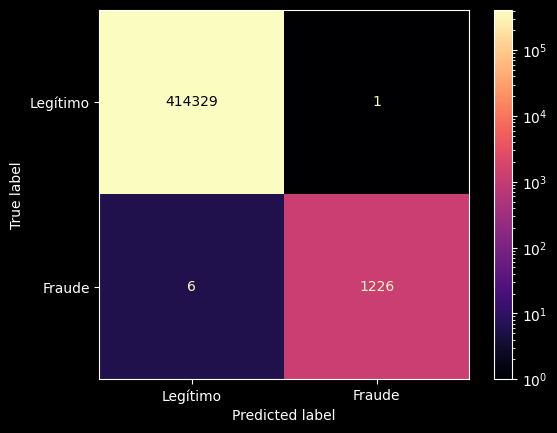

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
from matplotlib.colors import LogNorm

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred,
    display_labels=['Legítimo', 'Fraude'],
    cmap='magma',                      # ou 'Purples', 'viridis', 'Blues'
    values_format='d',
    im_kw={'norm': LogNorm(vmin=1)}    # escala logarítmica para colorir todos os quadrantes
)

plt.savefig('assets/Confusion_Matrix.png', dpi=300, bbox_inches='tight', facecolor='#121212')
plt.show()

In [ ]:
## Curva Precision-Recall AUC

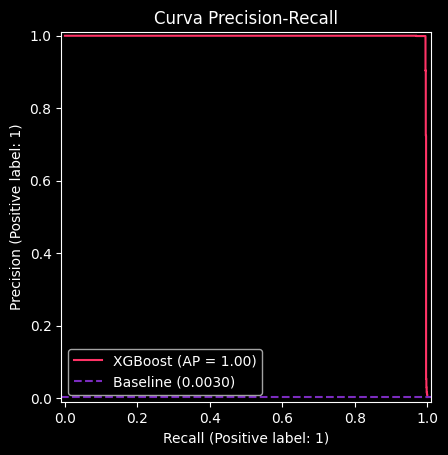

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay


display = PrecisionRecallDisplay.from_predictions(
    y_test,
    y_pred_proba,
    name="XGBoost",
    color="#FF3366"
)


baseline = y_test.mean()
display.ax_.axhline(baseline, color="#7B2CBF", linestyle="--", label=f"Baseline ({baseline:.4f})")

display.ax_.set_title("Curva Precision-Recall")
display.ax_.legend(loc="lower left")
plt.savefig('assets/ROC_Display.png', dpi=300, bbox_inches='tight', facecolor='#121212')
plt.show()

#Explicabilidade do modelo

In [ ]:
import shap

In [ ]:
#GERANDO O EXPLICADOR

explainer = shap.Explainer(xgb)

# CALCULAR OS VALORES PARA O CONJUNTO DE TESTE

shap_values= explainer(x_test)


## Explicação Global do Modelo

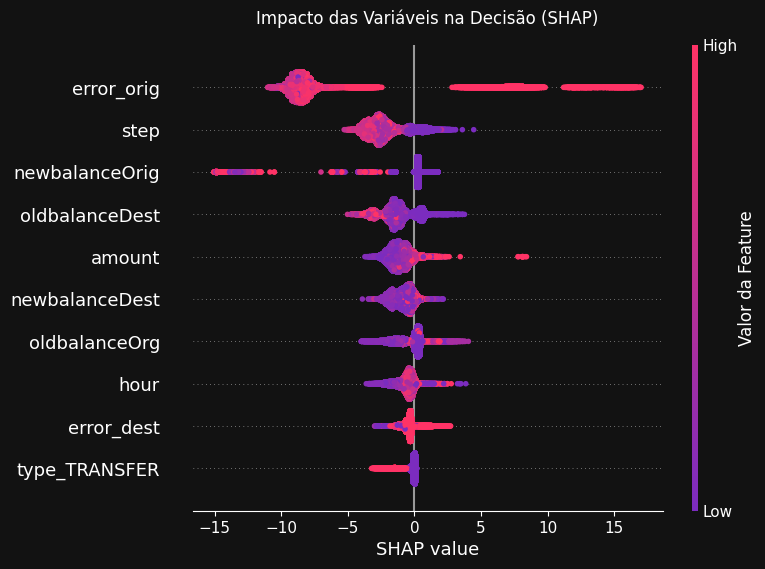

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('custom', ['#7B2CBF', '#FF3366'])

plt.figure(figsize=(10, 6), facecolor='#121212')
ax = plt.gca()
ax.set_facecolor('#121212')

shap.summary_plot(shap_values, x_test, max_display=10, cmap=cmap, show=False)

plt.title('Impacto das Variáveis na Decisão (SHAP)', color='white', pad=15)
plt.xlabel('SHAP value', color='white')
ax.tick_params(colors='white')

cb = plt.gcf().axes[-1]
cb.tick_params(colors='white')
cb.set_ylabel('Valor da Feature', color='white')

os.makedirs('assets', exist_ok=True)
plt.savefig('assets/shap_summary.png', dpi=300, bbox_inches='tight', facecolor='#121212')
plt.show()

## Explicação local

In [ ]:
instancia = 104

x_test.iloc[instancia:instancia+1]

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,hour,day_of_month,error_orig,error_dest,dest_zero_flag,type_TRANSFER
2741408,670,929106.32,3.456042,-0.104034,-0.27065,-0.119773,22,28,0.0,0.0,0,0.0


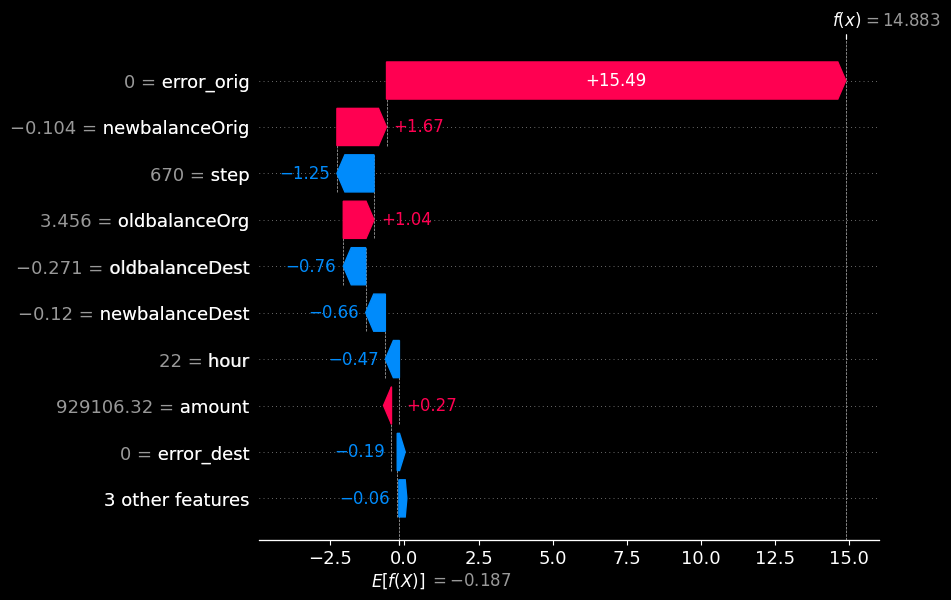

In [ ]:
shap.initjs()

exp_individual = shap.Explanation(
    values=shap_values[instancia].values,
    base_values=explainer.expected_value,
    data=x_test.iloc[instancia],
    feature_names=x_test.columns
)

shap.plots.waterfall(exp_individual, show=False)
plt.savefig('assets/shap_waterfall.png', bbox_inches='tight')
plt.show()